In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
#read csv file
df = pd.read_csv('D:\\NLP\Project\\Loan_Advisor_Chatbot\\Data\\raw\\loan_intents.csv')
df.head()

,text,intent
0,I want to know can someone with my income get ...,loan_eligibility
1,Why was my loan rejected right now,loan_rejection
2,Could you tell me can I close my loan early pl...,foreclosure
3,Could you help me understand how can I apply f...,loan_application
4,Could you tell me i need a loan for college in...,education_loan


In [8]:
df.shape

(3000, 2)

In [9]:
df.isnull().sum()

text      0
intent    0
dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

In [11]:
df['text'].duplicated().sum()

np.int64(0)

In [16]:
df.columns

Index(['text', 'intent'], dtype='object')

In [12]:
df['intent'].nunique()

25

In [13]:
df['intent'].unique()

array(['loan_eligibility', 'loan_rejection', 'foreclosure',
       'loan_application', 'education_loan', 'loan_types',
       'emi_calculation', 'business_loan', 'prepayment', 'existing_loan',
       'coapplicant', 'income_requirement', 'interest_rate',
       'credit_score', 'home_loan', 'loan_top_up', 'processing_fee',
       'required_documents', 'loan_tenure', 'goodbye', 'car_loan',
       'loan_amount', 'application_status', 'greeting', 'personal_loan'],
      dtype=object)

# **Intent Distribution**

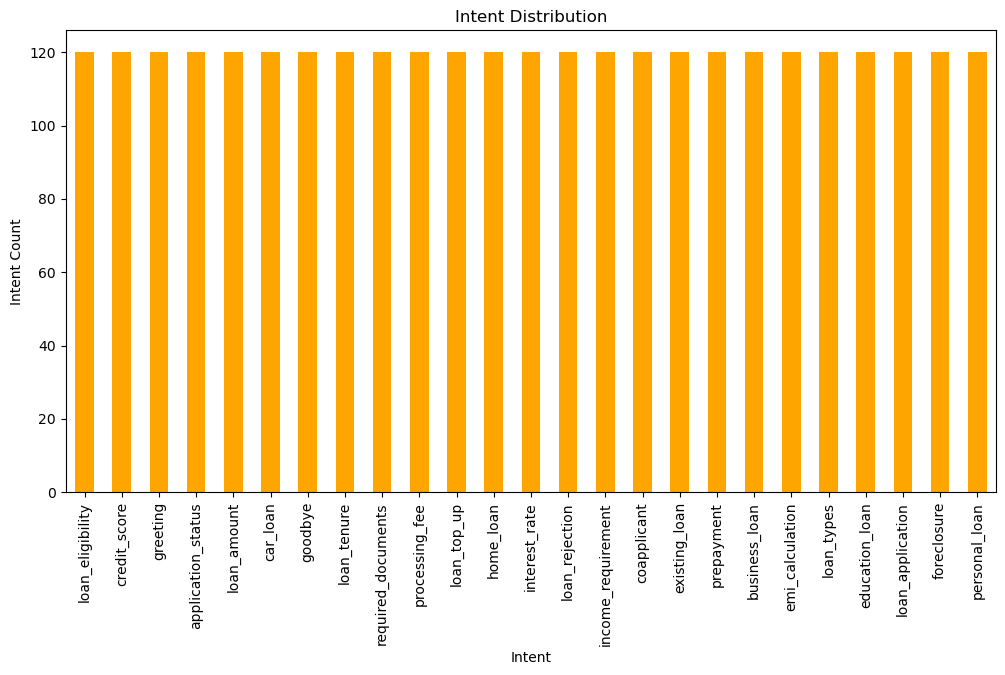

In [15]:
intent_count = df['intent'].value_counts()

plt.figure(figsize=(12, 6))

intent_count.plot(kind='bar',color='orange')
plt.title('Intent Distribution')
plt.xlabel('Intent')
plt.ylabel('Intent Count')
plt.show()

# **Text length analysis**

In [18]:
df['text_length'] = df['text'].str.len()
df['text_length'].describe()

count    3000.000000
mean       60.971333
std        12.665254
min        20.000000
25%        52.000000
50%        61.000000
75%        70.000000
max       103.000000
Name: text_length, dtype: float64

# **Word Count Analysis**

In [19]:
df['word_count'] = df['text'].str.split().str.len()
df['word_count'].describe()

count    3000.000000
mean       12.295333
std         2.510554
min         4.000000
25%        11.000000
50%        12.000000
75%        14.000000
max        20.000000
Name: word_count, dtype: float64

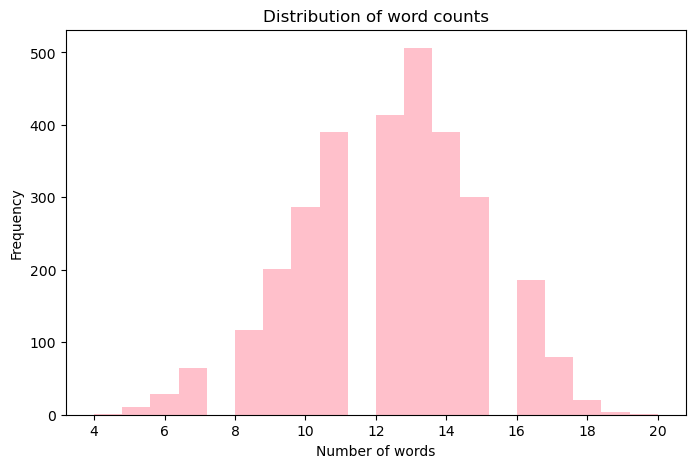

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df['word_count'],bins=20,color='pink')
plt.title('Distribution of word counts')
plt.xlabel('Number of words')
plt.ylabel('Frequency')
plt.show()

# **Find Shortest Sentense**

In [21]:
df.sort_values("word_count").head(10)[["text","intent"]]

,text,intent
1860,Explain business loan options,business_loan
1766,What are the foreclosure charges,foreclosure
2687,Explain business loan options please,business_loan
543,What causes loan rejection please,loan_rejection
2939,Tell me about business loans,business_loan
16,Does my CIBIL history matter,credit_score
2255,What percentage interest is charged,interest_rate
1131,"Okay, thanks for the information",goodbye
2607,Tell me about education loans,education_loan
300,Can I prepay my loan,prepayment


# **Find longest Sentensse**

In [22]:
df.sort_values("word_count",ascending=False).head(10)[["text","intent"]]

,text,intent
194,I would like to know i want to know whether I ...,loan_eligibility
2696,I would like to know can I get a top up on my ...,loan_top_up
2890,"I would like to know i already have a loan, ca...",existing_loan
1031,Could you help me understand how much will the...,processing_fee
358,I would like to know can I apply for a top up ...,loan_top_up
578,Could you help me understand is there a limit ...,loan_amount
288,I would like to know can I get a loan of ten l...,loan_amount
2711,Can you tell me can I get a top up on my exist...,loan_top_up
197,Could you help me understand can I add a co ap...,coapplicant
378,Could you tell me is there a limit on the amou...,loan_amount


In [25]:
for intent in df['intent'].unique():
    print("\n")
    print("="*60)
    print("intent:",intent)
    print("="*60)
    
    print(df[df['intent']==intent]['text'].sample(5).to_string())
                 



intent: loan_eligibility
2473    Could you tell me what are the eligibility req...
2132    Please tell me do I meet the eligibility crite...
1521    Could you help me understand what are the elig...
942     Can you explain am I eligible for a personal l...
2477    Could you tell me am I eligible for a personal...


intent: loan_rejection
1877    Please tell me why did my loan application get...
178     Could you tell me why did my loan application ...
68      I want to know why was my loan rejected in detail
2000    Can you explain why did my loan application ge...
2273    Could you tell me what are common reasons for ...


intent: foreclosure
2175    Please tell me how can I repay the entire loan...
1755    Could you help me understand what is the proce...
2262    Could you tell me what are the foreclosure cha...
1984    I want to know can I settle my loan before mat...
937                   Can I close my loan early in detail


intent: loan_application
1529                         

# **Analyse text length by intent**

In [24]:
df.groupby("intent")["word_count"].mean().sort_values()

intent
personal_loan         11.075000
business_loan         11.166667
goodbye               11.450000
loan_rejection        11.591667
car_loan              11.658333
loan_types            11.741667
foreclosure           11.950000
income_requirement    11.966667
education_loan        11.975000
interest_rate         12.033333
prepayment            12.108333
emi_calculation       12.150000
loan_tenure           12.350000
required_documents    12.408333
home_loan             12.441667
loan_application      12.450000
application_status    12.541667
loan_amount           12.600000
coapplicant           12.808333
credit_score          12.916667
processing_fee        12.925000
greeting              13.033333
loan_top_up           13.058333
loan_eligibility      13.408333
existing_loan         13.575000
Name: word_count, dtype: float64